In [67]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [68]:
# Load the Iris flower dataset
iris = load_iris()

# Store input measurements and target labels
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

# Display the first five rows
print("First five rows of the dataset:")
display(X.head())

print("\nDataset shape:", X.shape)
print("Species names:", iris.target_names)

First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Dataset shape: (150, 4)
Species names: ['setosa' 'versicolor' 'virginica']


In [69]:
# Add species names to the dataset
df = X.copy()
df["species"] = [
    iris.target_names[i] for i in y
]

# Check dataset information
print("Dataset Information:")
print(df.info())

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Count flowers in each species
print("\nSpecies Counts:")
print(df["species"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species Counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


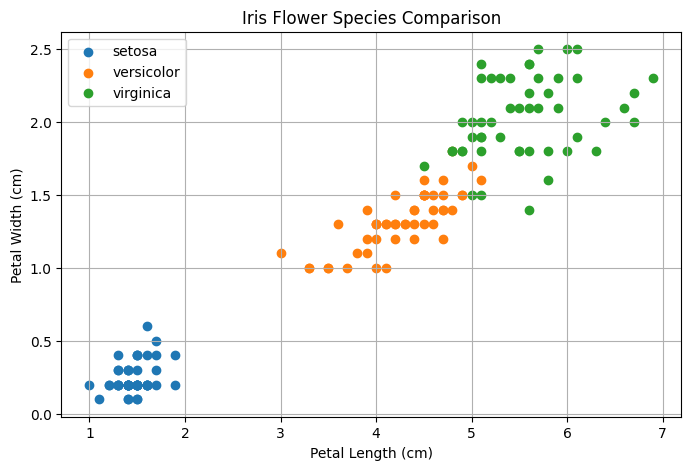

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for species in iris.target_names:
    subset = df[df["species"] == species]

    plt.scatter(
        subset["petal length (cm)"],
        subset["petal width (cm)"],
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Flower Species Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [71]:
from sklearn.model_selection import train_test_split

# Separate input features and target labels
X = df[iris.feature_names]
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training samples: 120
Testing samples: 30
Training data shape: (120, 4)
Testing data shape: (30, 4)


In [72]:
from sklearn.ensemble import RandomForestClassifier

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [73]:
from sklearn.metrics import accuracy_score, classification_report

# Predict flower species using test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Display detailed performance
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

Model Accuracy: 90.00%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



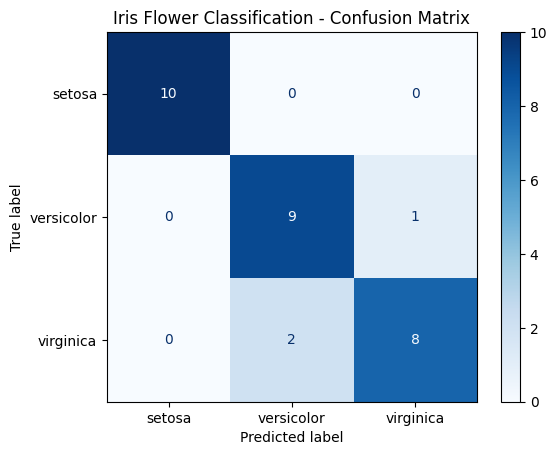

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Iris Flower Classification - Confusion Matrix")
plt.show()

In [75]:
```python
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Iris Flower Classification - Confusion Matrix")
plt.show()
```

SyntaxError: invalid syntax (3648205545.py, line 1)

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Iris Flower Classification - Confusion Matrix")
plt.show()

In [ ]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = model.predict(new_flower)[0]

print("Predicted flower species:",
      iris.target_names[prediction])

In [76]:

import joblib

joblib.dump(model, "iris_model.pkl")

print("Model saved successfully!")


Model saved successfully!
